In [25]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from keras.models import Sequential
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

## Evaluation of Data without augmentation

In [26]:
data = pd.read_csv("../example_dataset.csv")
testing_data = pd.read_csv("../example_testing_dataset.csv")

classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    
testing_data["steel_class"] = [classes_dict[c] for c in testing_data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")

for column in testing_data.columns:
        for index, value in testing_data[column].items():
            if isinstance(value, str):
                testing_data.at[index, column] = value.replace(",", ".")
                
data = data.map(pd.to_numeric)
testing_data = testing_data.map(pd.to_numeric)

In [27]:
# create X and y
X = data.drop(columns="steel_class")
y = data["steel_class"]

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

In [28]:
X_testing_data = testing_data.iloc[:,:-1]
y_testing_data = testing_data.iloc[:,-1]
label_encoder = LabelEncoder()
y_testing_data = label_encoder.fit_transform(y_testing_data)

In [29]:
model = Sequential()
model.add(Dense(248, activation='relu', input_dim=data.shape[1] - 1))
model.add(Dense(124, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.05)))

model.add(Dense(32, activation='relu'))

model.add(Dense(len(label_encoder.classes_), activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


model.fit(X, y, epochs=800, batch_size=8, validation_data=(X_testing_data, y_testing_data))

Epoch 1/800


C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.4417 - loss: 5.4791 - val_accuracy: 0.0084 - val_loss: 4.9788
Epoch 2/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4780 - loss: 4.4755 - val_accuracy: 0.0084 - val_loss: 4.4370
Epoch 3/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.4518 - loss: 3.6618 - val_accuracy: 0.0084 - val_loss: 4.0314
Epoch 4/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4976 - loss: 2.9755 - val_accuracy: 0.0084 - val_loss: 3.5184
Epoch 5/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4822 - loss: 2.5144 - val_accuracy: 0.0611 - val_loss: 3.0304
Epoch 6/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5956 - loss: 2.0160 - val_accuracy: 0.0940 - val_loss: 2.6471
Epoch 7/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6402 - loss: 1.7209 - val_accuracy: 0.1268 - val_loss: 2.3449
Epoch 8/800
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6697 - loss: 1.5175 - val_accuracy: 0.1658 - val_l

In [30]:
prediction_raw = model.predict(X_testing_data)
predictions = prediction_raw.argmax(axis=-1)

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


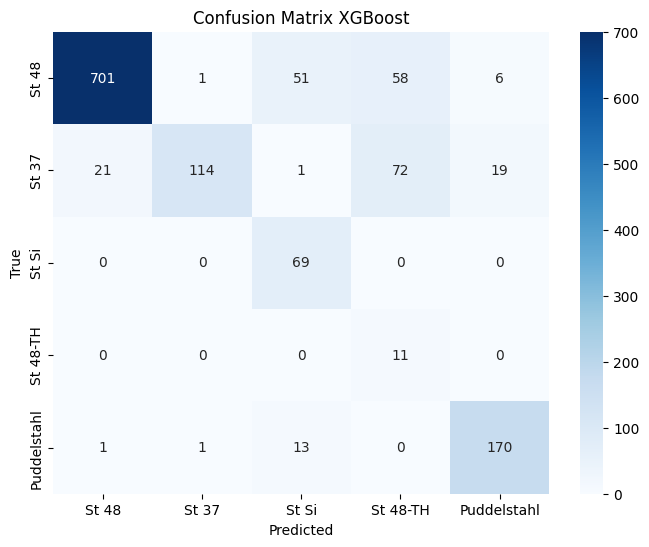

In [41]:
# build Confusion Matrix
conf_matrix = confusion_matrix(y_testing_data, predictions)
{"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
# print Confusion Martix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix XGBoost')
plt.savefig('Pre_Augment_Confusion_Matrix_NN.jpg', format='jpg')

plt.show()

In [32]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]

report = classification_report(y_testing_data, predictions, target_names=new_labels)

print(report)

              precision    recall  f1-score   support

       St 48       0.97      0.86      0.91       817
       St 37       0.98      0.50      0.66       227
       St Si       0.51      1.00      0.68        69
    St 48-TH       0.08      1.00      0.14        11
 Puddelstahl       0.87      0.92      0.89       185

    accuracy                           0.81      1309
   macro avg       0.68      0.86      0.66      1309
weighted avg       0.93      0.81      0.85      1309



<br>

## Evaluation of Data with augmentation 

In [42]:
data = pd.read_csv("../example_dataset.csv_with_augmented_data_SMOTE_ENN.csv")
#data = pd.read_csv("../example_dataset.csv_with_augmented_data_WGANs.csv")

testing_data = pd.read_csv("../example_testing_dataset.csv")

classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    
testing_data["steel_class"] = [classes_dict[c] for c in testing_data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")

for column in testing_data.columns:
        for index, value in testing_data[column].items():
            if isinstance(value, str):
                testing_data.at[index, column] = value.replace(",", ".")
                
data = data.map(pd.to_numeric)
testing_data = testing_data.map(pd.to_numeric)

In [43]:
# create X and y
X = data.drop(columns="steel_class")
y = data["steel_class"]

In [44]:
model_aug = Sequential()
model_aug.add(Dense(248, activation='relu', input_dim=data.shape[1] - 1))
model_aug.add(Dense(124, activation='relu'))
model_aug.add(Dropout(0.5))

model_aug.add(Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.05)))

model_aug.add(Dense(32, activation='relu'))

model_aug.add(Dense(len(label_encoder.classes_), activation='softmax'))

model_aug.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


model_aug.fit(X, y, epochs=800, batch_size=8, validation_data=(X_testing_data, y_testing_data))

Epoch 1/800


C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


70/70 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.4100 - loss: 4.7211 - val_accuracy: 0.6967 - val_loss: 2.4374
Epoch 2/800
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7513 - loss: 1.8126 - val_accuracy: 0.7930 - val_loss: 0.9720
Epoch 3/800
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8328 - loss: 0.7574 - val_accuracy: 0.8182 - val_loss: 0.5602
Epoch 4/800
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8096 - loss: 0.5127 - val_accuracy: 0.8258 - val_loss: 0.5143
Epoch 5/800
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8672 - loss: 0.4254 - val_accuracy: 0.9060 - val_loss: 0.4282
Epoch 6/800
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9432 - loss: 0.3225 - val_accuracy: 0.9198 - val_loss: 0.3910
Epoch 7/800
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9605 - loss: 0.2870 - val_accuracy: 0.9121 - val_loss: 0.3860
Epoch 8/800
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9753 - loss: 0.2151 - val_accuracy: 0.9030 - val_loss: 0.4

In [45]:
prediction_raw = model_aug.predict(X_testing_data)
predictions_augmented = prediction_raw.argmax(axis=-1)

41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


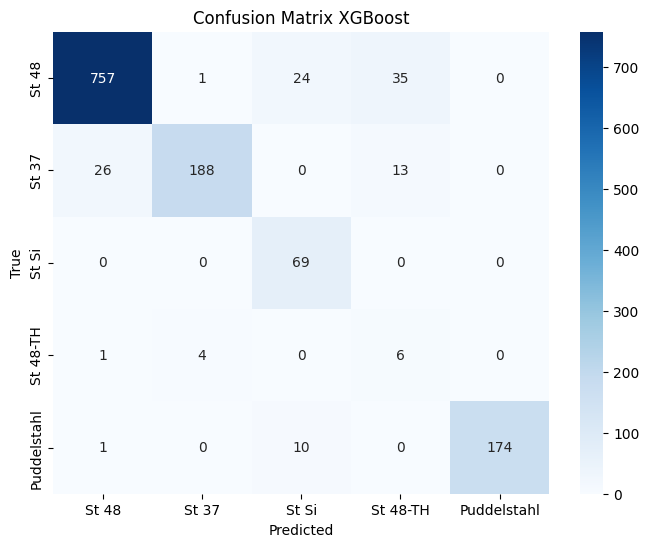

In [46]:
# build Confusion Matrix
conf_matrix = confusion_matrix(y_testing_data, predictions_augmented)
{"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
# print Confusion Martix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"], yticklabels=["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix XGBoost')
plt.savefig('SMOTE_ENN_Post_augment_Confusion_Matrix_NN.jpg', format='jpg')

plt.show()

In [47]:
new_labels = ["St 48", "St 37", "St Si", "St 48-TH", "Puddelstahl"]

report = classification_report(y_testing_data, predictions_augmented, target_names=new_labels)

print(report)

              precision    recall  f1-score   support

       St 48       0.96      0.93      0.95       817
       St 37       0.97      0.83      0.90       227
       St Si       0.67      1.00      0.80        69
    St 48-TH       0.11      0.55      0.18        11
 Puddelstahl       1.00      0.94      0.97       185

    accuracy                           0.91      1309
   macro avg       0.74      0.85      0.76      1309
weighted avg       0.95      0.91      0.93      1309

